# Experiment 4 — Hypothesis Testing (Iris Dataset)

**Covers:** Welch's t-test, z-test, Chi-square test, ANOVA, Tukey HSD, plots, p-value decisions, summary and CSV export.

**Dataset:** **Iris** – `Iris.csv` from Kaggle ([uciml/iris](https://www.kaggle.com/datasets/uciml/iris)), 150 flowers, columns `Id, SepalLengthCm, SepalWidthCm, PetalLengthCm, PetalWidthCm, Species`.

**Data file:** keep `Iris.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\Iris.csv")`).

**Remember:** ttest_ind → ztest → crosstab + chi2_contingency → f_oneway → pairwise_tukeyhsd.

## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, chi2_contingency, f_oneway
from statsmodels.stats.weightstats import ztest
from statsmodels.stats.multicomp import pairwise_tukeyhsd

df = pd.read_csv("Iris.csv")

## Decision rule
If p < 0.05 → reject H0, otherwise fail to reject H0.

- **T / Z-test** H0: versicolor and virginica have the same mean sepal width
- **Chi-square** H0: petal size (long/short) is independent of species
- **ANOVA** H0: all three species have the same mean sepal length

In [2]:
# Iris has one categorical column, so make a second one for the Chi-square test
df["PetalSize"] = np.where(df["PetalLengthCm"] > df["PetalLengthCm"].median(), "Long", "Short")


def decide(p):
    return "Reject H0" if p < 0.05 else "Fail to reject H0"

## 1. T-test: `SepalWidthCm` by `Species` (Iris-versicolor vs Iris-virginica)

Iris-versicolor: 50 2.77 0.314
Iris-virginica: 50 2.974 0.322


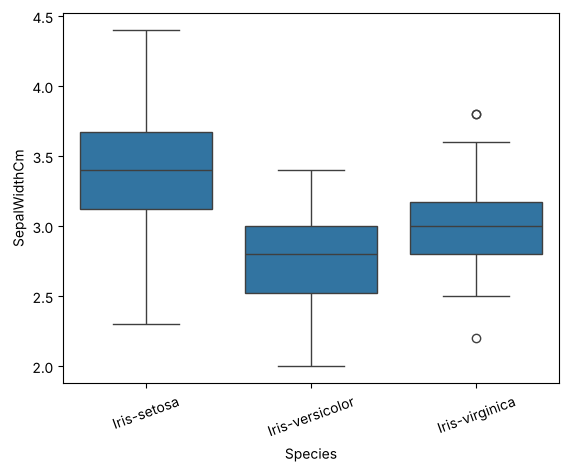

T-test: -3.2057607502218186 0.0018194834821049707 Reject H0


In [3]:
g1 = df[df["Species"] == "Iris-versicolor"]["SepalWidthCm"].dropna()
g2 = df[df["Species"] == "Iris-virginica"]["SepalWidthCm"].dropna()

print("Iris-versicolor:", len(g1), round(g1.mean(), 3), round(g1.std(), 3))
print("Iris-virginica:", len(g2), round(g2.mean(), 3), round(g2.std(), 3))

sns.boxplot(data=df, x="Species", y="SepalWidthCm")
plt.xticks(rotation=20)
plt.show()

t, p1 = ttest_ind(g1, g2, equal_var=False)
print("T-test:", t, p1, decide(p1))

## 2. Z-test: same two groups (large-sample test of means)

In [4]:
z, p2 = ztest(g1, g2)
print("Z-test:", z, p2, decide(p2))

Z-test: -3.2057607502218186 0.0013470593843806311 Reject H0


## 3. Chi-square: `Species` vs `PetalSize`

PetalSize        Long  Short
Species                     
Iris-setosa         0     50
Iris-versicolor    25     25
Iris-virginica     50      0


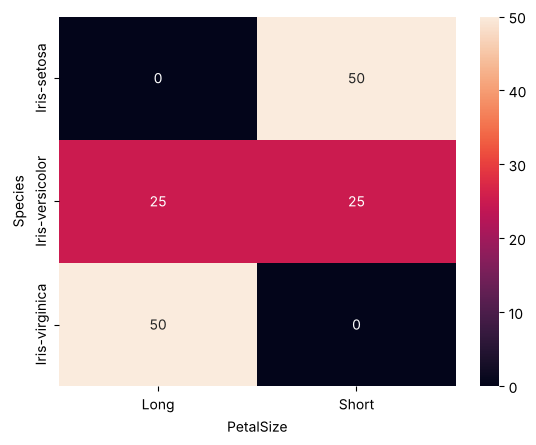

Chi-square: 100.0 DOF: 2 p: 1.9287498479639183e-22 Reject H0
Expected frequencies: [[25. 25.]
 [25. 25.]
 [25. 25.]]
Expected cells >= 5: 100.0 %


In [5]:
table = pd.crosstab(df["Species"], df["PetalSize"])
print(table)

sns.heatmap(table, annot=True, fmt="d")
plt.show()

chi, p3, dof, expected = chi2_contingency(table)
print("Chi-square:", chi, "DOF:", dof, "p:", p3, decide(p3))
print("Expected frequencies:", expected.round(1))
print("Expected cells >= 5:", (expected >= 5).mean() * 100, "%")

## 4. ANOVA: `SepalLengthCm` by `Species`

                 count   mean
Species                      
Iris-setosa         50  5.006
Iris-versicolor     50  5.936
Iris-virginica      50  6.588


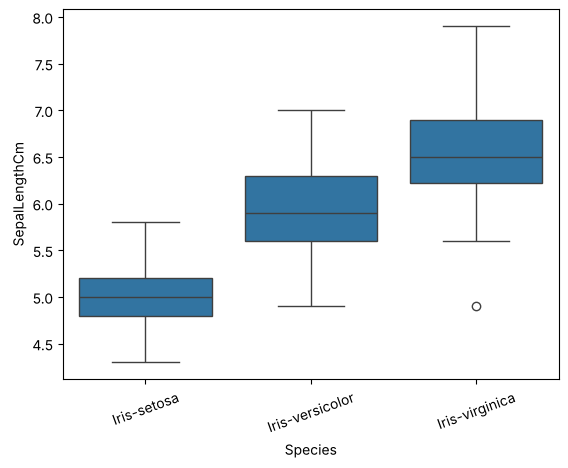

ANOVA: 119.26450218450472 1.6696691907693648e-31 Reject H0


In [6]:
groups = [g["SepalLengthCm"].dropna() for _, g in df.groupby("Species")]

print(df.groupby("Species")["SepalLengthCm"].agg(["count", "mean"]))
sns.boxplot(data=df, x="Species", y="SepalLengthCm")
plt.xticks(rotation=20)
plt.show()

f, p4 = f_oneway(*groups)
print("ANOVA:", f, p4, decide(p4))

## 5. Tukey HSD (which pairs differ?)

In [7]:
print(pairwise_tukeyhsd(df["SepalLengthCm"], df["Species"]))

        Multiple Comparison of Means - Tukey HSD, FWER=0.05        
     group1          group2     meandiff p-adj lower  upper  reject
-------------------------------------------------------------------
    Iris-setosa Iris-versicolor     0.93   0.0 0.6862 1.1738   True
    Iris-setosa  Iris-virginica    1.582   0.0 1.3382 1.8258   True
Iris-versicolor  Iris-virginica    0.652   0.0 0.4082 0.8958   True
-------------------------------------------------------------------


## 6. Summary and save

In [8]:
result = pd.DataFrame({
    "Test": ["T-test", "Z-test", "Chi-square", "ANOVA"],
    "Statistic": [t, z, chi, f],
    "P-value": [p1, p2, p3, p4],
    "Decision": [decide(p) for p in [p1, p2, p3, p4]]
})
print(result)

result.to_csv("hypothesis.csv", index=False)
print("Saved hypothesis.csv")

         Test   Statistic       P-value   Decision
0      T-test   -3.205761  1.819483e-03  Reject H0
1      Z-test   -3.205761  1.347059e-03  Reject H0
2  Chi-square  100.000000  1.928750e-22  Reject H0
3       ANOVA  119.264502  1.669669e-31  Reject H0
Saved hypothesis.csv


## Result / Conclusion
- **T-test / Z-test:** virginica has a wider sepal than versicolor (2.974 vs 2.770 cm, t = −3.21, p = 0.002) → reject H0.
- **Chi-square:** petal size depends strongly on species (χ² = 100, p ≈ 2e-22): setosa is always short, virginica always long. All expected counts are ≥ 5.
- **ANOVA:** mean sepal length differs between species (F = 119.3, p ≈ 2e-31).
- **Tukey HSD:** all three pairs of species differ significantly.